In [15]:
import os
import pandas as pd
import numpy as np

In [16]:
dataset_dir = "Bank_loan_dataset"
train_path = os.path.join(dataset_dir, "credit_train.csv")
test_path = os.path.join(dataset_dir, "credit_test.csv")

In [17]:
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

In [18]:
print(f"Training Data Shape: {train_df.shape} (Rows, Columns)")
print(f"Testing Data Shape: {test_df.shape} (Rows, Columns)\n")

Training Data Shape: (100514, 19) (Rows, Columns)
Testing Data Shape: (10353, 18) (Rows, Columns)



In [19]:
train_cols = set(train_df.columns)
test_cols = set(test_df.columns)
target_col = train_cols - test_cols

print(f"{list(target_col)}")

['Loan Status']


In [20]:
print(train_df.head())

                                Loan ID                           Customer ID  \
0  14dd8831-6af5-400b-83ec-68e61888a048  981165ec-3274-42f5-a3b4-d104041a9ca9   
1  4771cc26-131a-45db-b5aa-537ea4ba5342  2de017a3-2e01-49cb-a581-08169e83be29   
2  4eed4e6a-aa2f-4c91-8651-ce984ee8fb26  5efb2b2b-bf11-4dfd-a572-3761a2694725   
3  77598f7b-32e7-4e3b-a6e5-06ba0d98fe8a  e777faab-98ae-45af-9a86-7ce5b33b1011   
4  d4062e70-befa-4995-8643-a0de73938182  81536ad9-5ccf-4eb8-befb-47a4d608658e   

  Loan Status  Current Loan Amount        Term  Credit Score  Annual Income  \
0  Fully Paid             445412.0  Short Term         709.0      1167493.0   
1  Fully Paid             262328.0  Short Term           NaN            NaN   
2  Fully Paid           99999999.0  Short Term         741.0      2231892.0   
3  Fully Paid             347666.0   Long Term         721.0       806949.0   
4  Fully Paid             176220.0  Short Term           NaN            NaN   

  Years in current job Home Ownership 

In [21]:
print(f"Duplicate rows: {train_df.duplicated().sum()}")

Duplicate rows: 10728


In [22]:
missing_counts = train_df.isnull().sum()
print(missing_counts[missing_counts > 0])

Loan ID                           514
Customer ID                       514
Loan Status                       514
Current Loan Amount               514
Term                              514
Credit Score                    19668
Annual Income                   19668
Years in current job             4736
Home Ownership                    514
Purpose                           514
Monthly Debt                      514
Years of Credit History           514
Months since last delinquent    53655
Number of Open Accounts           514
Number of Credit Problems         514
Current Credit Balance            514
Maximum Open Credit               516
Bankruptcies                      718
Tax Liens                         524
dtype: int64


In [23]:
print(train_df['Loan Status'].value_counts(normalize=True) * 100)

Loan Status
Fully Paid     77.361
Charged Off    22.639
Name: proportion, dtype: float64


In [24]:
train_df['Current Loan Amount'] = train_df['Current Loan Amount'].replace(99999999, np.nan)
train_df['Current Loan Amount'] = train_df['Current Loan Amount'].fillna(train_df['Current Loan Amount'].median())

train_df = train_df.dropna(subset=['Loan ID'])

train_df = train_df.drop_duplicates()

if train_df['Years in current job'].dtype == 'object':
    train_df['Years in current job'] = train_df['Years in current job'].str.extract(r'(\d+)').astype(float)
else:
    train_df['Years in current job'] = pd.to_numeric(train_df['Years in current job'], errors='coerce')
train_df['Years in current job'] = train_df['Years in current job'].fillna(train_df['Years in current job'].median())

train_df['Credit Score'] = train_df['Credit Score'].fillna(train_df['Credit Score'].median())

train_df['Annual Income'] = train_df['Annual Income'].fillna(train_df['Annual Income'].median())

train_df['Bankruptcies'].fillna(0)

train_df['Tax Liens'].fillna(0)

if 'Months since last delinquent' in train_df.columns:
    train_df = train_df.drop(columns=['Months since last delinquent'])

    

In [25]:
print(f"{train_df.shape[0]}")

89784


In [26]:
print(f"{train_df.isnull().sum().sum()}")

201


In [27]:
train_df['Credit Score'] = train_df['Credit Score'].apply(lambda x: x / 10 if x > 850 else x)

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

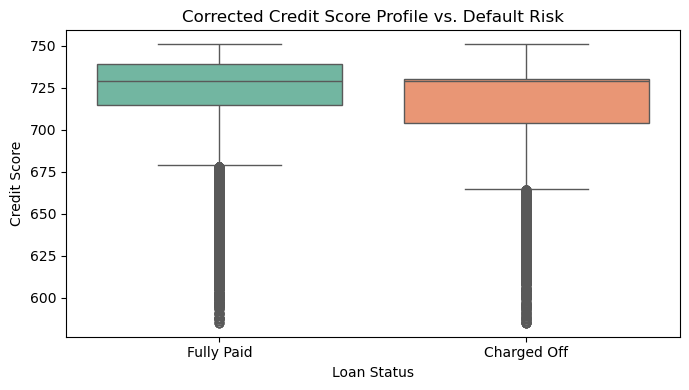

In [29]:
plt.figure(figsize=(7,4))
sns.boxplot(data = train_df.dropna(subset=['Loan Status', 'Credit Score']),
    x='Loan Status',
    y = 'Credit Score',
    hue = 'Loan Status',
    palette = 'Set2', 
    legend = False)
plt.title('Corrected Credit Score Profile vs. Default Risk')
plt.xlabel('Loan Status')
plt.ylabel('Credit Score')
plt.tight_layout()
plt.show()

In [30]:
print(train_df['Credit Score'].describe())

count    89784.000000
mean       720.802704
std         25.309630
min        585.000000
25%        713.000000
50%        729.000000
75%        737.000000
max        751.000000
Name: Credit Score, dtype: float64


In [31]:
train_df['Loan Status'] = train_df['Loan Status'].map({'Fully Paid':1, 'Charged Off' : 0})

features_df = pd.get_dummies(train_df, columns = ['Term', 'Home Ownership', 'Purpose'], drop_first = True)

In [32]:
X = features_df.drop(columns=['Loan Status'])
y = features_df['Loan Status']

In [35]:
non_numeric_cols = X.select_dtypes(exclude=[np.number]).columns
if len(non_numeric_cols) > 0:
    print(f"Automatically removing remaining text columns: {list(non_numeric_cols)}")
    X = X.drop(columns=non_numeric_cols)

In [36]:
X = X.fillna(0).astype(float)
y = y.astype(int)

In [37]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42, stratify = y
)

In [38]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, random_state=42,class_weight='balanced')
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [40]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_prob),4))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

ROC-AUC Score: 0.6872

Classification Report:
               precision    recall  f1-score   support

           0       0.47      0.07      0.12      4528
           1       0.76      0.97      0.85     13429

    accuracy                           0.75     17957
   macro avg       0.61      0.52      0.48     17957
weighted avg       0.68      0.75      0.67     17957



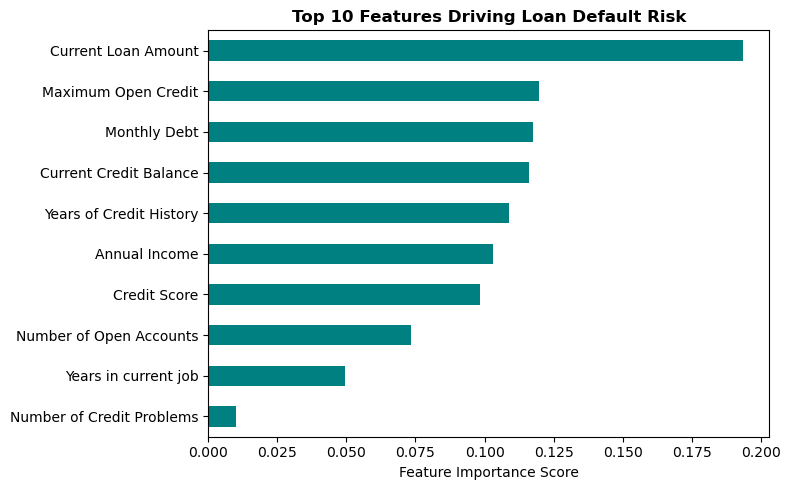

In [41]:
importances = pd.Series(model.feature_importances_, index=X.columns)
top_features = importances.nlargest(10).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
top_features.plot(kind='barh', color='teal')
plt.title('Top 10 Features Driving Loan Default Risk', fontweight='bold')
plt.xlabel('Feature Importance Score')
plt.tight_layout()
plt.show()

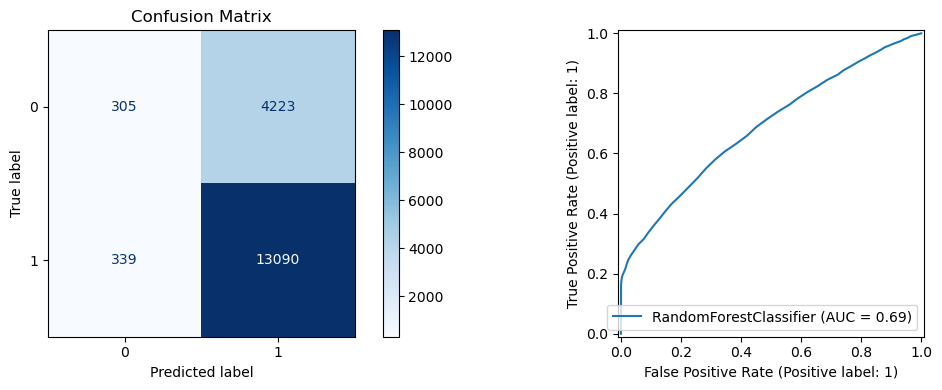

In [44]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(12,4))

ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap = 'Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix')

RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[1])

plt.tight_layout()
plt.show()

In [46]:
import joblib

joblib.dump(model, 'loan_default_model.pkl')
print("Model saved successfully!")

Model saved successfully!


In [52]:
export_df = X_test.copy()
export_df['Actual_Loan_Status'] = y_test.values
export_df['Predicted_Default'] = model.predict(X_test)
export_df['Default_Probability'] = model.predict_proba(X_test)[:, 1].round(4)

export_df['Risk_Category'] = pd.cut(
    export_df['Default_Probability'],
    bins=[0, 0.3, 0.7, 1.0],
    labels=['Low Risk', 'Medium Risk', 'High Risk'],
    include_lowest=True
)

export_df.to_csv('loan_predictions_master.csv', index=False)
print("Exported loan_predictions_master.csv successfully!")


Exported loan_predictions_master.csv successfully!


In [53]:
import sqlite3
import pandas as pd

# 1. Load your exported CSV and create a local SQLite database
df = pd.read_csv('loan_predictions_master.csv')
conn = sqlite3.connect('loan_portfolio.db')
df.to_sql('loan_data', conn, if_exists='replace', index=False)

# 2. Run your business validation query
query = """
SELECT 
    Risk_Category,
    COUNT(*) AS borrower_count,
    ROUND(AVG(Default_Probability) * 100, 2) AS avg_predicted_risk_pct,
    ROUND(AVG(Actual_Loan_Status) * 100, 2) AS actual_default_rate_pct
FROM loan_data
GROUP BY Risk_Category
ORDER BY actual_default_rate_pct DESC;
"""

print(pd.read_sql_query(query, conn))


  Risk_Category  borrower_count  avg_predicted_risk_pct  \
0     High Risk           11276                   83.74   
1   Medium Risk            6676                   61.32   
2      Low Risk               5                   29.00   

   actual_default_rate_pct  
0                    81.92  
1                    62.78  
2                    20.00  
